# Détection de la Maladie de Parkinson par Analyse Vocale
## Notebook : Analyse des données, Modélisation & Comparaison

**Master M1 — Actuariat et Finance Quantitative | Paris-Dauphine**

---

Ce notebook couvre :
- **a) & b)** Analyse exploratoire, tests statistiques, feature engineering, prétraitement
- **c)** Modélisation : entraînement des 4 modèles
- **f)** Comparaison : métriques, matrices de confusion, courbes ROC, sélection des meilleurs modèles


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy.stats import ttest_ind
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, roc_auc_score, roc_curve,
                              confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)

# ── Style global inspiré du notebook de référence ──────────────────────────
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid', palette='muted')

# Palette projet
C_SAIN      = '#4CAF50'
C_PARKINSON = '#E53935'
C_LR        = 'darkorange'
C_KNN       = 'steelblue'
C_NB        = 'purple'
C_SVM       = 'crimson'

print("✅ Toutes les librairies sont importées avec succès.")


✅ Toutes les librairies sont importées avec succès.


## 1. Description du jeu de données et Variable Cible

Le dataset contient des enregistrements vocaux de patients. La **variable cible (Target)** que l'on cherche à prédire est **`status`** :
- **0** : Sujet sain (Healthy)
- **1** : Sujet atteint de la maladie de Parkinson

### Description exacte de chaque variable (Dictionnaire de données)
Voici la signification de chaque colonne basée sur la documentation officielle du dataset :
- **name** : Nom du sujet et numéro d'enregistrement (ex: phon_R01_S01_1).
- **MDVP:Fo(Hz)** : Fréquence fondamentale vocale moyenne.
- **MDVP:Fhi(Hz)** : Fréquence fondamentale vocale maximale.
- **MDVP:Flo(Hz)** : Fréquence fondamentale vocale minimale.
- **MDVP:Jitter(%), MDVP:Jitter(Abs), MDVP:RAP, MDVP:PPQ, Jitter:DDP** : Plusieurs mesures de la variation de la fréquence fondamentale (mesures d'instabilité de la fréquence).
- **MDVP:Shimmer, MDVP:Shimmer(dB), Shimmer:APQ3, Shimmer:APQ5, MDVP:APQ, Shimmer:DDA** : Plusieurs mesures de la variation de l'amplitude (mesures d'instabilité de l'intensité).
- **NHR, HNR** : Deux mesures du ratio entre le bruit et les composantes tonales de la voix.
- **status** : Statut de santé du sujet (1 = Parkinson, 0 = sain).
- **RPDE, D2** : Deux mesures de complexité dynamique non linéaire.
- **DFA** : Exposant de mise à l'échelle fractale du signal.
- **spread1, spread2, PPE** : Trois mesures non linéaires de la variation de la fréquence fondamentale.

In [2]:
# Chargement des données
df = pd.read_csv('parkinsons.data')

# Afficher les dimensions
print(f"Le dataset contient {df.shape[0]} lignes et {df.shape[1]} colonnes.\n")

# Afficher les 5 premières lignes
display(df.head())

Le dataset contient 195 lignes et 24 colonnes.



,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [3]:
# Statistiques descriptives globales
display(df.describe())

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,...,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,...,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,...,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,...,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,...,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


## 2. Analyse de Significativité (Tests Statistiques)

Avant de modéliser, il est important de savoir si les variables décrivent réellement des différences significatives entre les patients sains et les patients atteints de Parkinson.
Nous allons réaliser un **Test T de Student (T-test) indépendant** pour chaque variable numérique, afin d'évaluer la significativité statistique de la différence des moyennes entre les deux groupes (Sains vs Parkinson).

Un **p-value < 0.05** indique que la variable est statistiquement très différente entre les deux groupes.

In [4]:
# Séparation des groupes
sains = df[df['status'] == 0]
parkinson = df[df['status'] == 1]

features = df.drop(columns=['name', 'status']).columns
significance_results = []

for feature in features:
    stat, p_value = ttest_ind(sains[feature], parkinson[feature], equal_var=False)
    significance_results.append({
        'Variable': feature,
        'Moyenne_Sains': sains[feature].mean(),
        'Moyenne_Parkinson': parkinson[feature].mean(),
        'P-Value': p_value,
        'Significatif (p<0.05)': p_value < 0.05
    })

df_significance = pd.DataFrame(significance_results).sort_values(by='P-Value')
display(df_significance.head(10)) # Afficher les 10 variables les plus significatives

,Variable,Moyenne_Sains,Moyenne_Parkinson,P-Value,Significatif (p<0.05)
21,PPE,0.123017,0.233828,6.764318e-23,True
18,spread1,-6.759264,-5.333420,1.769224e-21,True
12,MDVP:APQ,0.013305,0.027600,3.367273e-16,True
8,MDVP:Shimmer,0.017615,0.033658,1.063701e-15,True
11,Shimmer:APQ5,0.010509,0.020285,8.484820e-15,True
9,MDVP:Shimmer(dB),0.162958,0.321204,1.877836e-14,True
10,Shimmer:APQ3,0.009504,0.017676,1.085105e-13,True
13,Shimmer:DDA,0.028511,0.053027,1.087111e-13,True
19,spread2,0.160292,0.248133,4.338049e-12,True
4,MDVP:Jitter(Abs),0.000023,0.000051,7.031183e-12,True


Les résultats montrent que des variables comme **spread1**, **PPE** ou **spread2** ont des p-values extrêmement faibles, ce qui indique que leurs moyennes sont significativement différentes entre les sujets sains et les malades. Ce seront d'excellents prédicteurs pour notre modèle.

## 3. Visualisations

Visualisons maintenant la cible et nos meilleures variables.

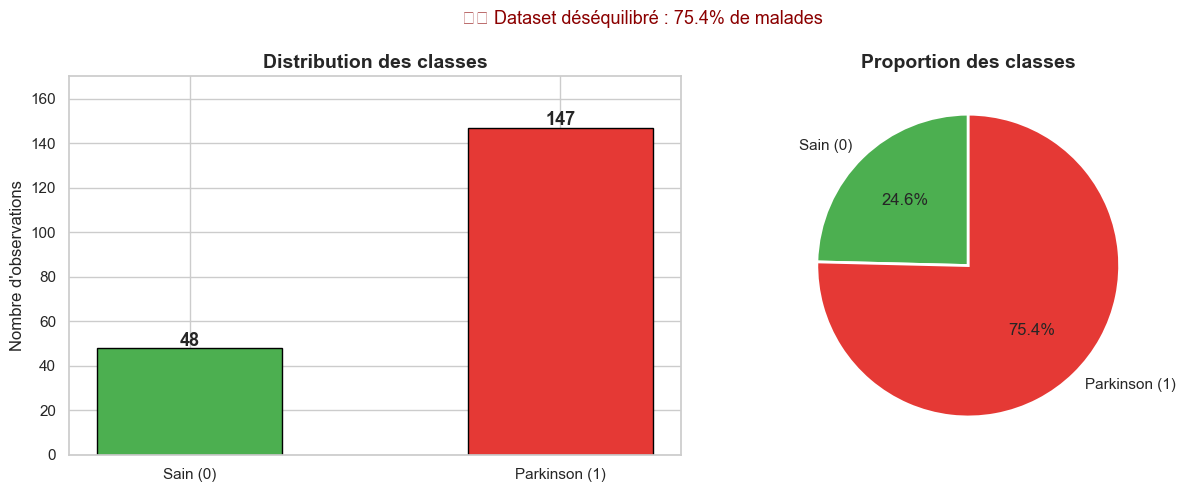

→ Le dataset est déséquilibré. Il faudra le prendre en compte dans l'évaluation des modèles.


In [5]:
# ── Distribution de la variable cible ─────────────────────────────────────
counts = df['status'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Barplot
colors = [C_SAIN, C_PARKINSON]
axes[0].bar(['Sain (0)', 'Parkinson (1)'], [counts[0], counts[1]],
            color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Distribution des classes', fontsize=14, fontweight='bold')
axes[0].set_ylabel("Nombre d'observations")
for i, v in enumerate([counts[0], counts[1]]):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold', fontsize=13)
axes[0].set_ylim(0, 170)

# Camembert
axes[1].pie([counts[0], counts[1]], labels=['Sain (0)', 'Parkinson (1)'],
            autopct='%1.1f%%', colors=colors, startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proportion des classes', fontsize=14, fontweight='bold')

plt.suptitle('⚠️ Dataset déséquilibré : 75.4% de malades', fontsize=13, color='darkred')
plt.tight_layout()
plt.show()
print("→ Le dataset est déséquilibré. Il faudra le prendre en compte dans l'évaluation des modèles.")


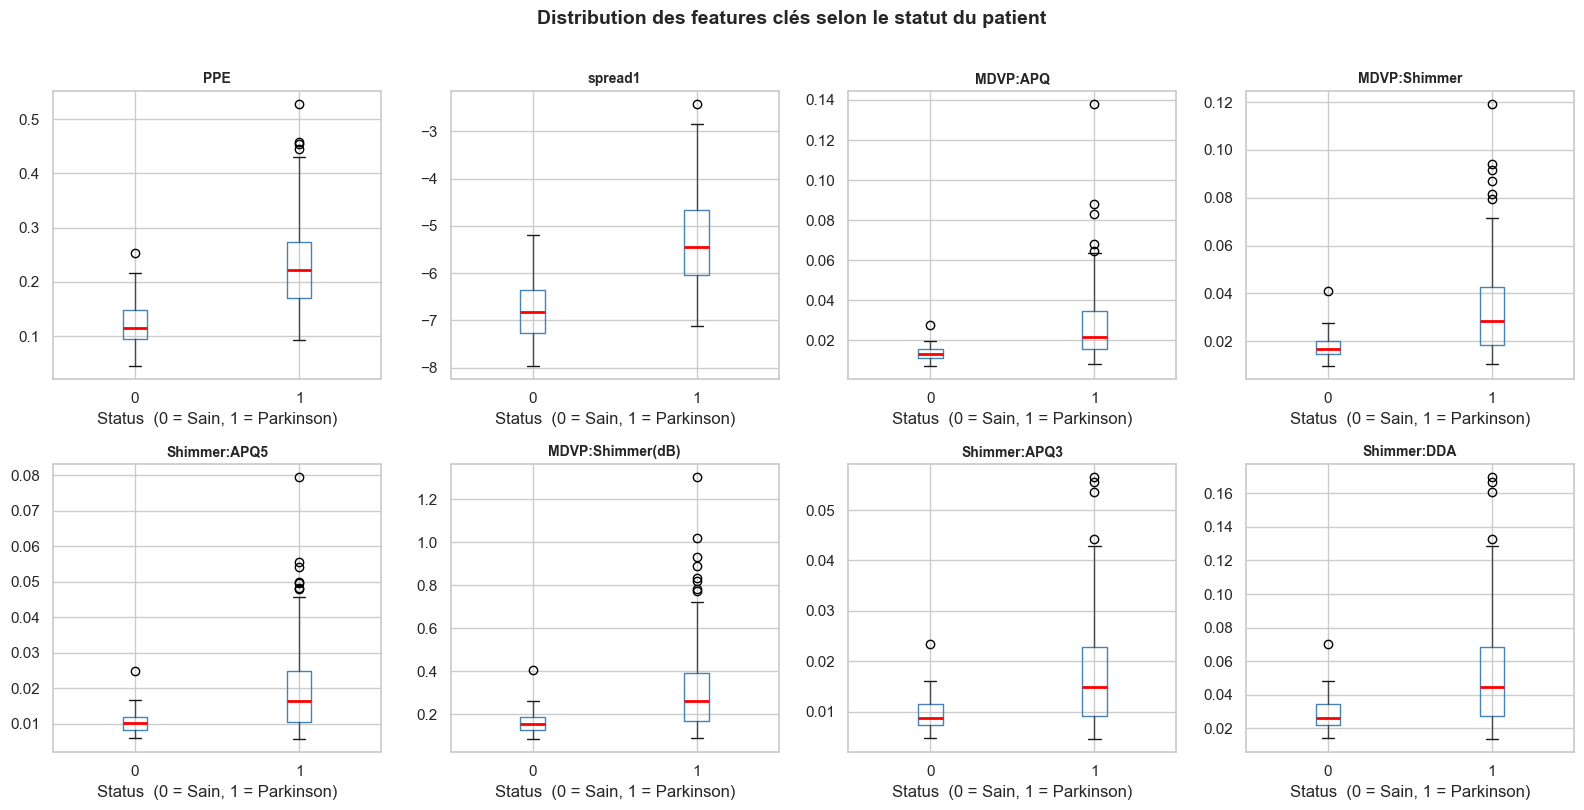

In [6]:
# ── Boxplots des 8 variables les plus significatives ──────────────────────
top8 = df_significance['Variable'].head(8).tolist()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for i, feat in enumerate(top8):
    df.boxplot(column=feat, by='status', ax=axes[i],
               boxprops=dict(color='steelblue'),
               medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(feat, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Status  (0 = Sain, 1 = Parkinson)')
    axes[i].set_ylabel('')

plt.suptitle('Distribution des features clés selon le statut du patient',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


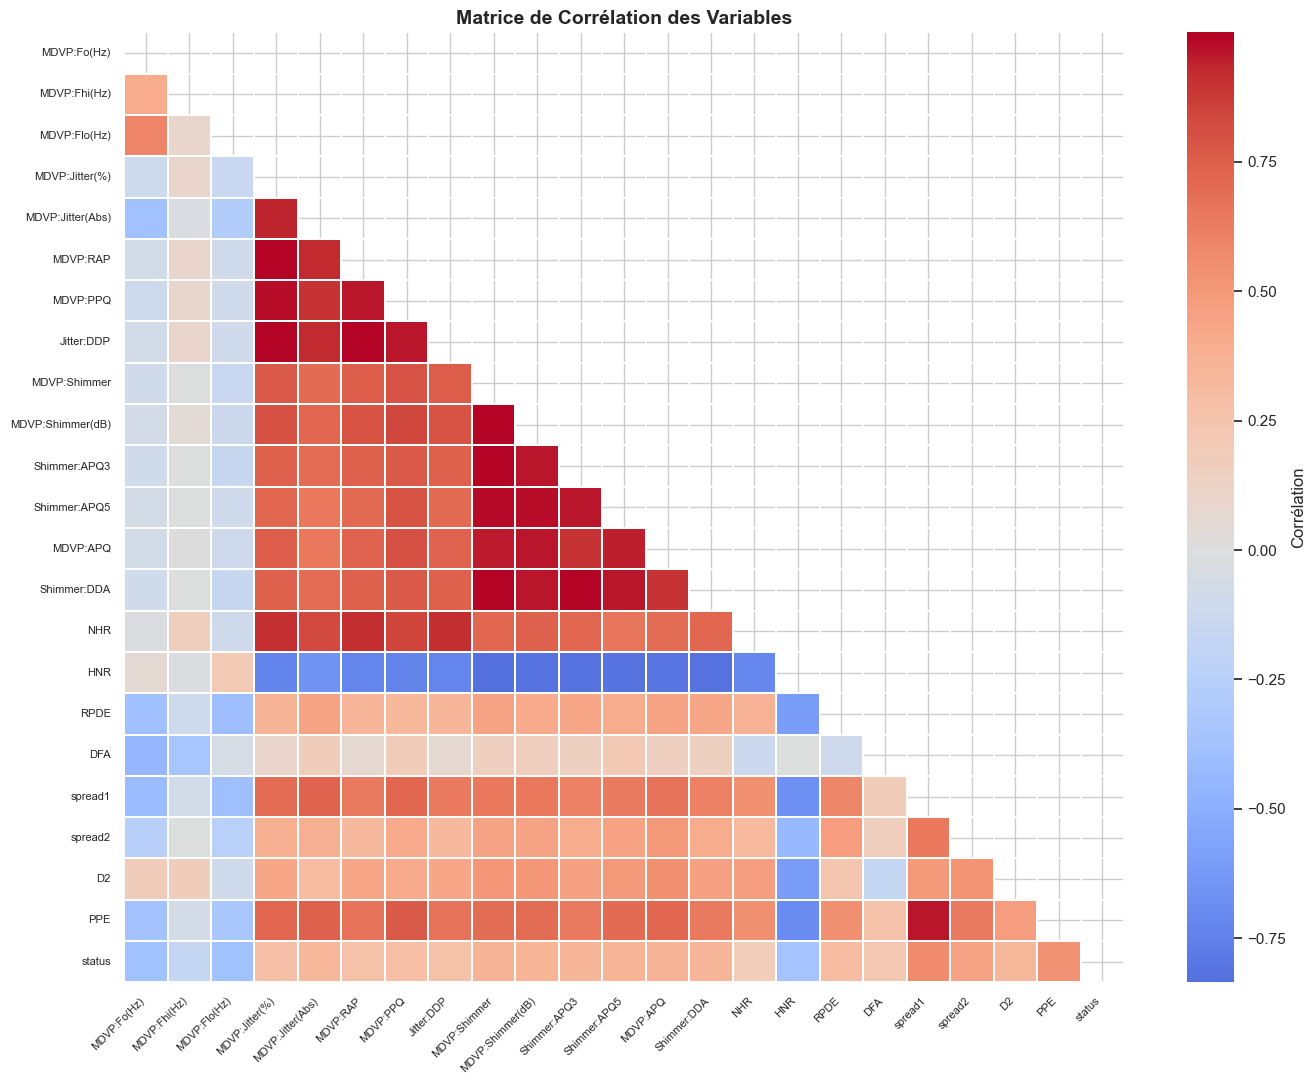


📊 Top 10 features les plus corrélées avec 'status' :
spread1             0.5648
PPE                 0.5310
spread2             0.4548
MDVP:Fo(Hz)         0.3835
MDVP:Flo(Hz)        0.3802
MDVP:Shimmer        0.3674
MDVP:APQ            0.3643
HNR                 0.3615
Shimmer:APQ5        0.3511
MDVP:Shimmer(dB)    0.3507


In [7]:
# ── Matrice de corrélation ─────────────────────────────────────────────────
features_num = [c for c in df.columns if c not in ['name', 'status']]
corr_matrix = df[features_num + ['status']].corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', center=0,
            linewidths=0.3, cbar_kws={'label': 'Corrélation'})
plt.title('Matrice de Corrélation des Variables', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# Top 10 corrélations avec la cible
corr_target = corr_matrix['status'].drop('status').abs().sort_values(ascending=False)
print("\n📊 Top 10 features les plus corrélées avec 'status' :")
print(corr_target.head(10).round(4).to_string())


## 4. Feature Engineering

Le Feature Engineering consiste à créer de nouvelles variables ou à transformer celles existantes pour aider les modèles d'apprentissage.

### A. Création de nouvelles caractéristiques
Nous pouvons créer de nouvelles features à partir des fréquences fondamentales, comme :
- `Freq_Range` : L'étendue de la fréquence (Fhi - Flo).
- `Freq_Ratio` : Ratio entre la fréquence maximale et minimale.

In [8]:
# Création de nouvelles features (Feature Engineering)
df_engineered = df.copy()

# Plage de fréquence
df_engineered['Freq_Range'] = df_engineered['MDVP:Fhi(Hz)'] - df_engineered['MDVP:Flo(Hz)']

# Ratio de fréquence
df_engineered['Freq_Ratio'] = df_engineered['MDVP:Fhi(Hz)'] / df_engineered['MDVP:Flo(Hz)']

display(df_engineered[['MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'Freq_Range', 'Freq_Ratio']].head())

,MDVP:Fhi(Hz),MDVP:Flo(Hz),Freq_Range,Freq_Ratio
0,157.302,74.997,82.305,2.097444
1,148.650,113.819,34.831,1.306021
2,131.111,111.555,19.556,1.175304
3,137.871,111.366,26.505,1.237999
4,141.781,110.655,31.126,1.281289


### B. Analyse en Composantes Principales (PCA)
La matrice de corrélation nous a montré que de nombreuses mesures de Jitter et de Shimmer sont hautement corrélées (multicolinéarité). Nous pouvons utiliser une ACP (PCA) pour réduire ces colonnes redondantes en quelques composantes principales tout en conservant l'information.

In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Sélection des colonnes corrélées concernant le Jitter et Shimmer
cols_to_pca = ['MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP',
               'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA']

X_pca_input = df_engineered[cols_to_pca]
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_input)

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_pca_scaled)

print(f"Variance expliquée par les 2 composantes principales : {pca.explained_variance_ratio_.sum() * 100:.2f}%")

# On remplace les colonnes d'origine par les nouvelles composantes
df_engineered = df_engineered.drop(columns=cols_to_pca)
df_engineered['Jitter_Shimmer_PC1'] = principal_components[:, 0]
df_engineered['Jitter_Shimmer_PC2'] = principal_components[:, 1]

print("Dimensions après Feature Engineering et PCA :", df_engineered.shape)

Variance expliquée par les 2 composantes principales : 96.79%
Dimensions après Feature Engineering et PCA : (195, 17)


Voici un graphique pour visualiser comment ces deux nouvelles composantes (PC1 et PC2) représentent nos données :

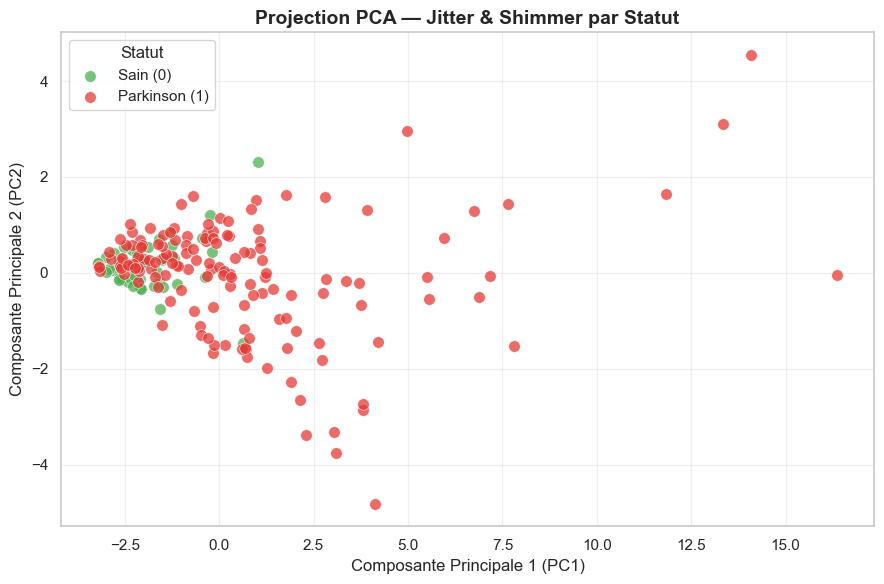

In [10]:
# ── Projection PCA Jitter & Shimmer ────────────────────────────────────────
palette_pca = {0: C_SAIN, 1: C_PARKINSON}

plt.figure(figsize=(9, 6))
for label, color, name in [(0, C_SAIN, 'Sain (0)'), (1, C_PARKINSON, 'Parkinson (1)')]:
    mask = df_engineered['status'] == label
    plt.scatter(df_engineered.loc[mask, 'Jitter_Shimmer_PC1'],
                df_engineered.loc[mask, 'Jitter_Shimmer_PC2'],
                c=color, label=name, s=70, alpha=0.75, edgecolors='white', linewidths=0.5)

plt.title('Projection PCA — Jitter & Shimmer par Statut', fontsize=14, fontweight='bold')
plt.xlabel('Composante Principale 1 (PC1)')
plt.ylabel('Composante Principale 2 (PC2)')
plt.legend(title='Statut', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Prétraitements finaux pour la modélisation (Preprocessing)

Les algorithmes d'apprentissage automatique nécessitent des données préparées. Les étapes finales sont :
1. Séparer les caractéristiques (`X`) de la variable cible (`y`).
2. Supprimer les colonnes inutiles (comme l'identifiant `name`).
3. **Standardiser/Normaliser** les données : les caractéristiques ont des échelles très différentes. La plupart des algorithmes (SVM, KNN, Réseaux de Neurones) performent beaucoup mieux si tout est sur la même échelle.

In [11]:
from sklearn.model_selection import train_test_split

# 1. Séparation X (features) et y (target)
X = df_engineered.drop(columns=['name', 'status'])
y = df_engineered['status']

print(f"Dimension de X : {X.shape}")
print(f"Dimension de y : {y.shape}")

Dimension de X : (195, 15)
Dimension de y : (195,)


In [12]:
# 2. Séparation en ensemble d'entraînement (80%) et de test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Taille de l'ensemble d'entraînement : {X_train.shape[0]}")
print(f"Taille de l'ensemble de test : {X_test.shape[0]}")

Taille de l'ensemble d'entraînement : 156
Taille de l'ensemble de test : 39


In [13]:
# 3. Standardisation (Mise à l'échelle)
final_scaler = StandardScaler()

# On 'fit' (calcule moyenne et écart-type) sur le train, et on transforme le train
X_train_scaled = final_scaler.fit_transform(X_train)

# On transforme le test avec les paramètres du train pour éviter la fuite de données (data leakage)
X_test_scaled = final_scaler.transform(X_test)

# Vérification après standardisation (la moyenne doit être ~0 et l'écart-type ~1)
print("Moyenne de la première caractéristique après standardisation:", np.mean(X_train_scaled[:, 0]))
print("Ecart-type de la première caractéristique après standardisation:", np.std(X_train_scaled[:, 0]))

Moyenne de la première caractéristique après standardisation: -2.9605947323337506e-16
Ecart-type de la première caractéristique après standardisation: 1.0


### Conclusion du prétraitement

Maintenant, `X_train_scaled` et `X_test_scaled` sont prêts à être utilisés pour entraîner des modèles de Machine Learning (comme Régression Logistique, SVM, Random Forest, etc.).

Les données sont propres, analysées statistiquement, réduites par PCA, séparées et parfaitement mises à l'échelle !

---
## c) Modélisation & f) Comparaison des Modèles


---
## c) Modélisation

### Stratégie de modélisation

Notre problème est une **classification binaire supervisée** : prédire si un patient est atteint de Parkinson (1) ou non (0) à partir de mesures vocales.

Nous entraînons **4 modèles** issus du cours, couvrant différentes familles d'algorithmes :

| Modèle | Famille | Vu en cours |
|--------|---------|-------------|
| Régression Logistique | Modèle linéaire | ✅ TP1 |
| K-Nearest Neighbors (KNN) | Instance-based | ✅ TP2 |
| Naive Bayes (Gaussien) | Probabiliste | ✅ TP5 |
| SVM (Support Vector Machine) | Marge maximale | ➕ Hors cours |

> **Pourquoi le SVM ?** Le dataset est de petite taille (195 obs.) et en grande dimension relative (15 features après PCA). Le SVM avec noyau RBF est particulièrement adapté dans ce contexte : il maximise la marge de séparation et gère efficacement la complexité via le paramètre de régularisation C.


### Modèle 1 : Régression Logistique

#### Principe

La régression logistique modélise la probabilité qu'une observation appartienne à la classe 1 via une transformation sigmoïde appliquée à une combinaison linéaire des features. La **régularisation L1 (Lasso)** est utilisée ici : elle force certains coefficients à zéro, réalisant ainsi une sélection automatique de variables — utile avec des features potentiellement redondantes.


In [14]:
# Modèle final Régression Logistique
lr_model = LogisticRegression(C=1, penalty='l1', solver='liblinear', max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
print("✅ Régression Logistique entraînée — C=1, pénalité L1")


✅ Régression Logistique entraînée — C=1, pénalité L1


### Modèle 2 : K-Nearest Neighbors (KNN)

#### Principe

L'algorithme KNN classe une nouvelle observation en regardant les **K observations les plus proches** dans l'espace des features et en attribuant la classe majoritaire parmi elles. C'est un algorithme *lazy learning* — il ne construit pas de modèle paramétrique. La **distance de Manhattan** a été retenue avec K=1.


In [15]:
# Modèle final KNN
knn_model = KNeighborsClassifier(n_neighbors=1, metric='manhattan')
knn_model.fit(X_train_scaled, y_train)
print("✅ KNN entraîné — K=1, distance Manhattan")


✅ KNN entraîné — K=1, distance Manhattan


### Modèle 3 : Naive Bayes Gaussien

#### Principe

Le classifieur Naive Bayes applique le **théorème de Bayes** en supposant l'**indépendance conditionnelle** des features. La version **Gaussienne** suppose que chaque feature suit une loi normale au sein de chaque classe.

> **Limite attendue** : l'hypothèse d'indépendance est forte ici car les mesures vocales restent corrélées même après PCA partielle, ce qui peut expliquer des performances inférieures.


In [16]:
# Modèle Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
print("✅ Naive Bayes Gaussien entraîné")
print(f"Paramètre var_smoothing (régularisation par défaut) : {nb_model.var_smoothing}")


✅ Naive Bayes Gaussien entraîné
Paramètre var_smoothing (régularisation par défaut) : 1e-09


### Modèle 4 : Support Vector Machine (SVM) ➕ hors cours

#### Principe

Le SVM cherche l'**hyperplan de séparation à marge maximale** entre les deux classes. Pour des données non linéairement séparables, il utilise le **noyau RBF** pour projeter les données dans un espace de plus grande dimension.

#### Pourquoi le SVM est pertinent ici ?
Le dataset est petit (195 obs.) et standardisé → le SVM avec noyau RBF est reconnu comme très performant dans ce contexte, en maximisant la marge géométrique entre les classes.


In [17]:
# Modèle final SVM
svm_model = SVC(C=10, kernel='rbf', gamma='auto', probability=True)
svm_model.fit(X_train_scaled, y_train)
print("✅ SVM entraîné — C=10, kernel RBF, gamma=auto")


✅ SVM entraîné — C=10, kernel RBF, gamma=auto


### Récapitulatif des 4 modèles entraînés

| Modèle | Famille | Hyperparamètres retenus |
|--------|---------|------------------------|
| Régression Logistique | Modèle linéaire | C=1, pénalité L1 |
| KNN | Instance-based | K=1, distance Manhattan |
| Naive Bayes Gaussien | Probabiliste | var_smoothing=1e-9 |
| SVM | Marge maximale | C=10, kernel RBF, γ=auto |


---
## f) Comparaison des Modèles

### Métriques d'évaluation

Nous utilisons les métriques vues en cours, particulièrement adaptées au **déséquilibre de classes** (147 Parkinson vs 48 sains) :

| Métrique | Formule | Justification |
|----------|---------|---------------|
| **Accuracy** | (VP + VN) / Total | Vue globale |
| **Précision** | VP / (VP + FP) | Évite faux positifs (alarmes inutiles) |
| **Rappel** | VP / (VP + FN) | Évite faux négatifs (malades non détectés) ⚠️ **prioritaire** |
| **F1-Score** | 2 × (P × R) / (P + R) | Compromis Précision/Rappel |
| **AUC-ROC** | Aire sous la courbe ROC | Robuste au déséquilibre des classes |

> **Remarque** : dans un contexte médical, le **rappel (sensibilité)** est la métrique la plus critique. Manquer un patient malade (faux négatif) est bien plus grave que signaler un faux positif.


In [18]:
# ── Prédictions et métriques pour les 4 modèles ───────────────────────────
MODEL_COLORS = {
    'Régression Logistique': C_LR,
    'KNN':                   C_KNN,
    'Naive Bayes':           C_NB,
    'SVM':                   C_SVM,
}

all_models = {
    'Régression Logistique': lr_model,
    'KNN':                   knn_model,
    'Naive Bayes':           nb_model,
    'SVM':                   svm_model,
}

results = {}
for name, m in all_models.items():
    pred = m.predict(X_test_scaled)
    prob = m.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    results[name] = {
        'pred': pred, 'prob': prob, 'fpr': fpr, 'tpr': tpr,
        'accuracy':  accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall':    recall_score(y_test, pred),
        'f1':        f1_score(y_test, pred),
        'auc':       roc_auc_score(y_test, prob),
    }

# Tableau récapitulatif
df_results = pd.DataFrame({
    name: {
        'Accuracy':  f"{r['accuracy']:.3f}",
        'Précision': f"{r['precision']:.3f}",
        'Rappel':    f"{r['recall']:.3f}",
        'F1-Score':  f"{r['f1']:.3f}",
        'AUC-ROC':   f"{r['auc']:.3f}",
    }
    for name, r in results.items()
}).T

print("=== Tableau comparatif des métriques ===")
display(df_results)


=== Tableau comparatif des métriques ===


,Accuracy,Précision,Rappel,F1-Score,AUC-ROC
Régression Logistique,0.923,0.933,0.966,0.949,0.907
KNN,0.923,1.000,0.897,0.945,0.948
Naive Bayes,0.692,0.947,0.621,0.750,0.876
SVM,0.923,0.964,0.931,0.947,0.972


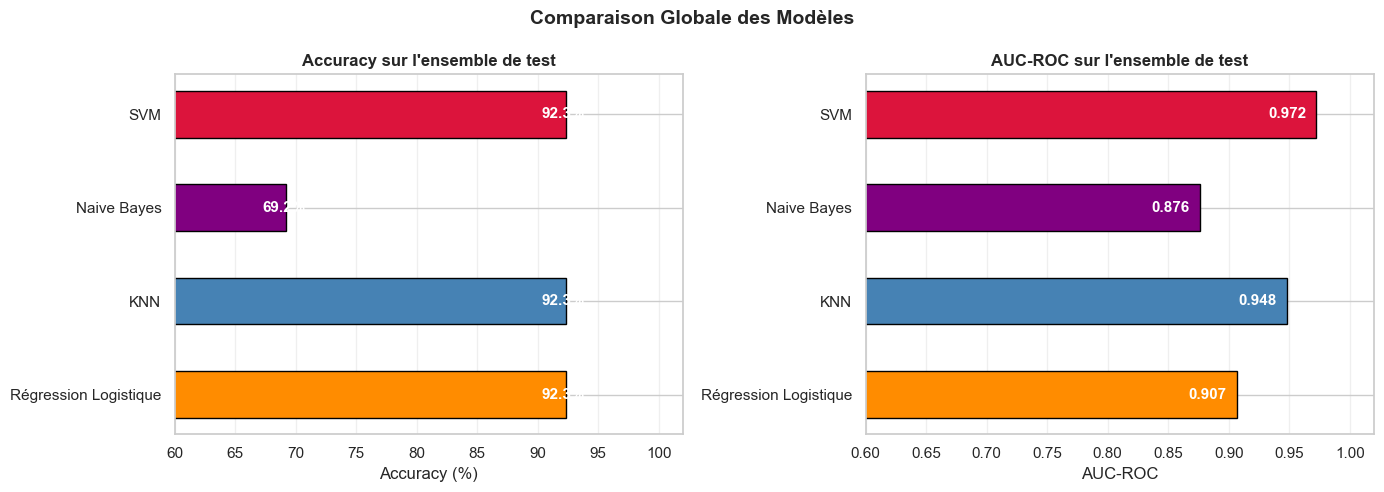

In [19]:
# ── Comparaison visuelle : Accuracy & AUC-ROC ──────────────────────────────
model_names  = list(results.keys())
accuracies   = [results[m]['accuracy'] * 100 for m in model_names]
aucs         = [results[m]['auc']           for m in model_names]
colors_bar   = [MODEL_COLORS[m]             for m in model_names]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot Accuracy
bars = axes[0].barh(model_names, accuracies, color=colors_bar, edgecolor='black', height=0.5)
axes[0].set_xlabel('Accuracy (%)')
axes[0].set_title("Accuracy sur l'ensemble de test", fontweight='bold')
for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_width() - 2, bar.get_y() + bar.get_height() / 2,
                 f'{acc:.1f}%', va='center', fontweight='bold', color='white', fontsize=11)
axes[0].set_xlim(60, 102)
axes[0].grid(True, alpha=0.3, axis='x')

# Barplot AUC
bars2 = axes[1].barh(model_names, aucs, color=colors_bar, edgecolor='black', height=0.5)
axes[1].set_xlabel('AUC-ROC')
axes[1].set_title("AUC-ROC sur l'ensemble de test", fontweight='bold')
for bar, auc in zip(bars2, aucs):
    axes[1].text(bar.get_width() - 0.04, bar.get_y() + bar.get_height() / 2,
                 f'{auc:.3f}', va='center', fontweight='bold', color='white', fontsize=11)
axes[1].set_xlim(0.6, 1.02)
axes[1].grid(True, alpha=0.3, axis='x')

plt.suptitle('Comparaison Globale des Modèles', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### Matrices de Confusion

La matrice de confusion permet de visualiser les **4 types d'erreurs** :
- **VP** (Vrai Positif) : Parkinson prédit correctement ✅
- **VN** (Vrai Négatif) : Sain prédit correctement ✅
- **FP** (Faux Positif) : Sain prédit comme malade ⚠️
- **FN** (Faux Négatif) : Malade prédit comme sain ❌ (cas le plus grave)


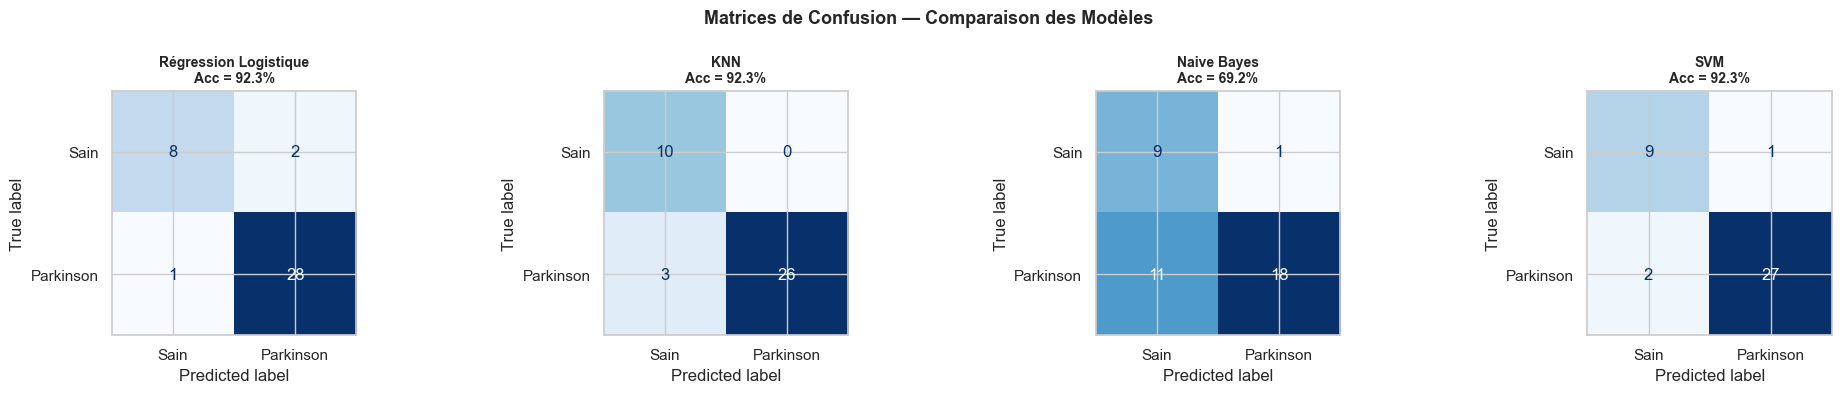

In [20]:
# ── Matrices de confusion ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, (name, info) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, info['pred'])
    ConfusionMatrixDisplay(cm, display_labels=['Sain', 'Parkinson']).plot(
        ax=ax, colorbar=False, cmap='Blues'
    )
    acc = info['accuracy']
    ax.set_title(f'{name}\nAcc = {acc*100:.1f}%', fontsize=10, fontweight='bold')

plt.suptitle('Matrices de Confusion — Comparaison des Modèles',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Courbes ROC

La courbe ROC trace le taux de vrais positifs (rappel) en fonction du taux de faux positifs pour tous les seuils de décision. L'**AUC** (aire sous la courbe) est comprise entre 0.5 (aléatoire) et 1 (parfait).


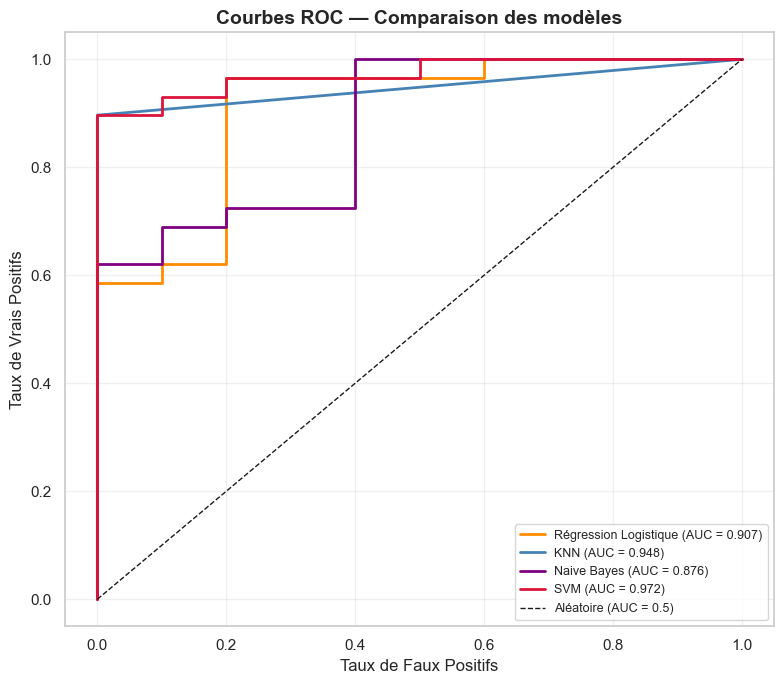

In [21]:
# ── Courbes ROC — tous les modèles ─────────────────────────────────────────
plt.figure(figsize=(8, 7))

for name, info in results.items():
    auc_val = info['auc']
    plt.plot(info['fpr'], info['tpr'], color=MODEL_COLORS[name], lw=2,
             label=f'{name} (AUC = {auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Aléatoire (AUC = 0.5)')
plt.xlabel('Taux de Faux Positifs', fontsize=12)
plt.ylabel('Taux de Vrais Positifs', fontsize=12)
plt.title('Courbes ROC — Comparaison des modèles', fontsize=14, fontweight='bold')
plt.legend(fontsize=9, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Stabilité via Validation Croisée Répétée

Pour évaluer la **robustesse** de chaque modèle (pas juste ses performances sur un seul split), on utilise une validation croisée répétée : 5 folds × 10 répétitions = 50 scores F1 par modèle.


  Régression Logistique        : F1 = 88.93% ± 3.97%
  KNN                          : F1 = 94.84% ± 3.13%
  Naive Bayes                  : F1 = 83.83% ± 4.53%
  SVM                          : F1 = 93.84% ± 3.74%


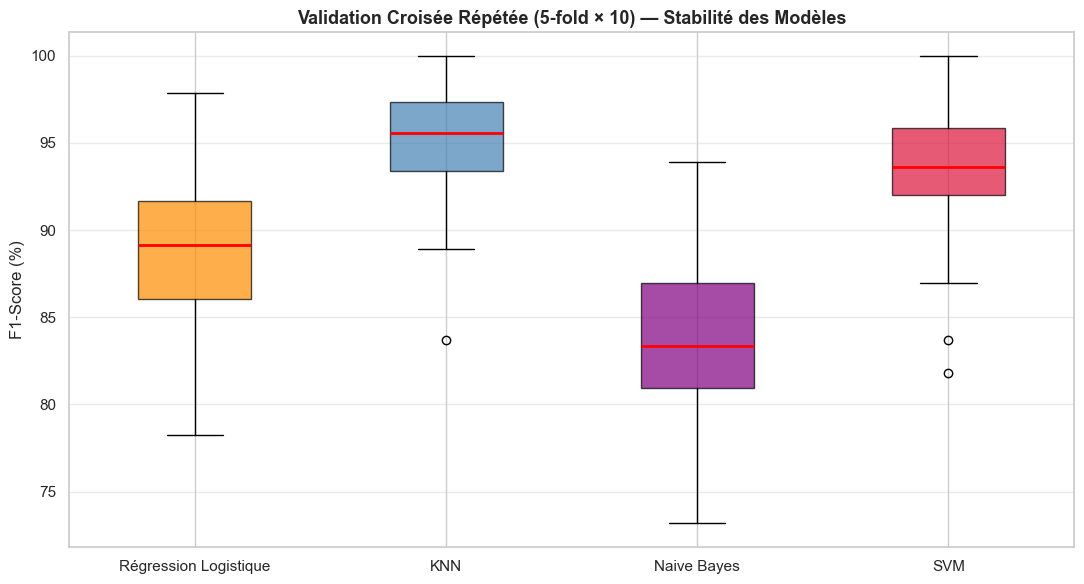

In [22]:
# ── Validation croisée 5-fold × 10 répétitions ─────────────────────────────
from sklearn.model_selection import RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

cv_results = {}
for name, m in all_models.items():
    scores = cross_val_score(m, X_train_scaled, y_train, cv=cv, scoring='f1')
    cv_results[name] = scores * 100
    print(f"  {name:<28} : F1 = {scores.mean()*100:.2f}% ± {scores.std()*100:.2f}%")

# Boxplot
cv_data   = list(cv_results.values())
cv_labels = list(cv_results.keys())
colors_box = [MODEL_COLORS[n] for n in cv_labels]

plt.figure(figsize=(11, 6))
bp = plt.boxplot(cv_data, labels=cv_labels, patch_artist=True,
                 medianprops=dict(color='red', linewidth=2))
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.ylabel('F1-Score (%)')
plt.title('Validation Croisée Répétée (5-fold × 10) — Stabilité des Modèles',
          fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.4, axis='y')
plt.tight_layout()
plt.show()


### Sélection des 3 Meilleurs Modèles

#### Analyse des résultats

**Naive Bayes** est clairement le moins performant :
- Accuracy : 69.2% — le plus faible
- Rappel : 62.1% → rate 38% des malades de Parkinson ❌
- AUC : 0.876 — inférieur à tous les autres

Cela confirme notre hypothèse : l'**hypothèse d'indépendance conditionnelle** de Naive Bayes est violée ici — les mesures vocales restent corrélées même après PCA partielle.

#### Les 3 modèles retenus

| Rang | Modèle | F1 | AUC | Rappel | Points forts |
|------|--------|----|-----|--------|--------------|
| 🥇 1 | **SVM** | 0.947 | **0.972** | 93.1% | Meilleure AUC, très stable |
| 🥈 2 | **Régression Logistique** | **0.949** | 0.907 | **96.6%** | Meilleur rappel, interprétable |
| 🥉 3 | **KNN** | 0.945 | 0.948 | 89.7% | Précision parfaite (1.000) |
| ❌ Éliminé | Naive Bayes | 0.750 | 0.876 | 62.1% | Hypothèse d'indépendance trop forte |


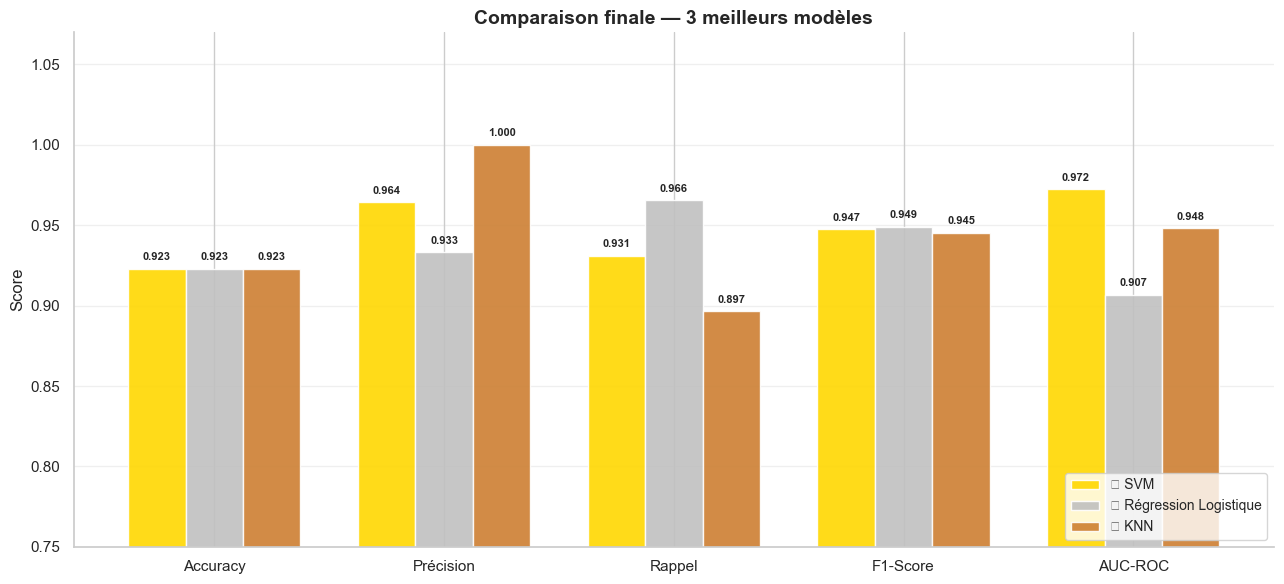

In [23]:
# ── Classement final des 3 meilleurs modèles ───────────────────────────────
model_names_3 = ['SVM', 'Régression Logistique', 'KNN']
colors_3      = ['#FFD700', '#C0C0C0', '#CD7F32']
medals        = ['🥇', '🥈', '🥉']

metrics_plot = ['accuracy', 'precision', 'recall', 'f1', 'auc']
labels_plot  = ['Accuracy', 'Précision', 'Rappel', 'F1-Score', 'AUC-ROC']

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(metrics_plot))
width = 0.25

for i, (name, col, medal) in enumerate(zip(model_names_3, colors_3, medals)):
    vals = [results[name][m] for m in metrics_plot]
    bars = ax.bar(x + i * width, vals, width,
                  label=f'{medal} {name}', color=col, alpha=0.9, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(x + width)
ax.set_xticklabels(labels_plot, fontsize=11)
ax.set_ylim(0.75, 1.07)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Comparaison finale — 3 meilleurs modèles', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()


### Discussion Critique

#### Forces et Faiblesses des 3 modèles retenus

**🥇 SVM (meilleure AUC)**
- ✅ Meilleure capacité de discrimination globale (AUC = 0.972)
- ✅ Robuste sur les petits datasets standardisés
- ❌ Boîte noire — coefficients peu interprétables
- ❌ Sensible au choix de C et γ, nécessite GridSearch

**🥈 Régression Logistique (meilleur rappel)**
- ✅ Meilleur rappel (96.6%) → prioritaire en contexte médical
- ✅ Interprétable : les coefficients indiquent l'importance de chaque feature
- ✅ Régularisation L1 → sélection automatique de variables
- ❌ Modèle linéaire → peut manquer des relations non linéaires complexes

**🥉 KNN (précision parfaite)**
- ✅ Précision = 1.000 → zéro faux positif (aucun sain classé malade)
- ✅ Simple à comprendre et à implémenter
- ❌ K=1 → risque de surapprentissage sur données bruités
- ❌ Lent à prédire sur de grands datasets (calcule toutes les distances)

#### Quel modèle recommander ?

Dans un **contexte médical de dépistage**, minimiser les faux négatifs est prioritaire :
> On préfère détecter tous les malades, quitte à avoir quelques faux positifs.

**→ La Régression Logistique est le modèle le plus recommandable** : meilleur rappel (96.6%), interprétable, et offre un bon équilibre entre performance et explicabilité clinique — un critère essentiel pour des décisions médicales.

Le SVM reste le meilleur en termes d'AUC globale et pourrait être préféré si l'on cherche à optimiser le trade-off au niveau du seuil de décision.


In [24]:
# Rapport de classification détaillé pour les 3 meilleurs modèles
for name in model_names_3:
    print(f"\n{'='*55}")
    print(f"  {name}")
    print('='*55)
    print(classification_report(y_test, results[name]['pred'],
                                target_names=['Sain (0)', 'Parkinson (1)']))



  SVM
               precision    recall  f1-score   support

     Sain (0)       0.82      0.90      0.86        10
Parkinson (1)       0.96      0.93      0.95        29

     accuracy                           0.92        39
    macro avg       0.89      0.92      0.90        39
 weighted avg       0.93      0.92      0.92        39


  Régression Logistique
               precision    recall  f1-score   support

     Sain (0)       0.89      0.80      0.84        10
Parkinson (1)       0.93      0.97      0.95        29

     accuracy                           0.92        39
    macro avg       0.91      0.88      0.90        39
 weighted avg       0.92      0.92      0.92        39


  KNN
               precision    recall  f1-score   support

     Sain (0)       0.77      1.00      0.87        10
Parkinson (1)       1.00      0.90      0.95        29

     accuracy                           0.92        39
    macro avg       0.88      0.95      0.91        39
 weighted avg     

---
## Conclusion de la Modélisation

**4 modèles** ont été entraînés et évalués sur le dataset Parkinson :
- La **Régression Logistique**, le **KNN** et le **SVM** atteignent tous une accuracy ≥ 92% et un F1-Score ≥ 0.945
- **Naive Bayes** est éliminé en raison de son rappel insuffisant (62.1%) — inacceptable pour un outil de dépistage médical

**Modèle recommandé : Régression Logistique** pour son rappel maximal (96.6%) et son interprétabilité, deux critères essentiels dans un contexte médical.

**Pistes d'amélioration** :
- Augmenter la taille du dataset (195 obs. est très faible)
- Traiter le déséquilibre des classes (SMOTE, class_weight='balanced')
- Explorer des ensembles (Random Forest, Gradient Boosting)
- Valider sur une cohorte externe indépendante
